In [1]:
import os
import re
import time
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

import lightgbm as lgb
import xgboost as xgb

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    LabelEncoder,
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler,
)

import warnings

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

print("All Set.")


All Set.


In [2]:
import os

DATA_PATH = os.path.abspath("../data")

print(f"Data directory detected: {DATA_PATH}")

train_raw = pd.read_csv(
    os.path.join(DATA_PATH, "train.csv"),
    low_memory=False,
)

test_raw = pd.read_csv(
    os.path.join(DATA_PATH, "test.csv"),
    low_memory=False,
)

sample_sub = pd.read_csv(
    os.path.join(DATA_PATH, "sample_submission.csv")
)

print(
    f"Train Dataset : {train_raw.shape[0]:,} rows × {train_raw.shape[1]} columns"
)

print(
    f"Test Dataset  : {test_raw.shape[0]:,} rows × {test_raw.shape[1]} columns"
)

Data directory detected: e:\HeavyEquipmentML\data
Train Dataset : 138,701 rows × 50 columns
Test Dataset  : 15,000 rows × 49 columns


In [3]:
print("=" * 60)
print("Training Dataset Overview")
print("=" * 60)
train_raw.info(max_cols=10)
print("\nTarget Variable Statistics")
print("-" * 60)
print(
    train_raw["TargetValue"].describe()
)

Training Dataset Overview
<class 'pandas.DataFrame'>
RangeIndex: 138701 entries, 0 to 138700
Columns: 50 entries, TransactionID to col30
dtypes: float64(2), int64(4), str(44)
memory usage: 82.7 MB

Target Variable Statistics
------------------------------------------------------------
count    138701.000000
mean      41521.874047
std       26361.125948
min        7500.000000
25%       20500.000000
50%       35000.000000
75%       57000.000000
max      142000.000000
Name: TargetValue, dtype: float64


Skewness (Original): 0.9700
Skewness (Log Scale): -0.1983


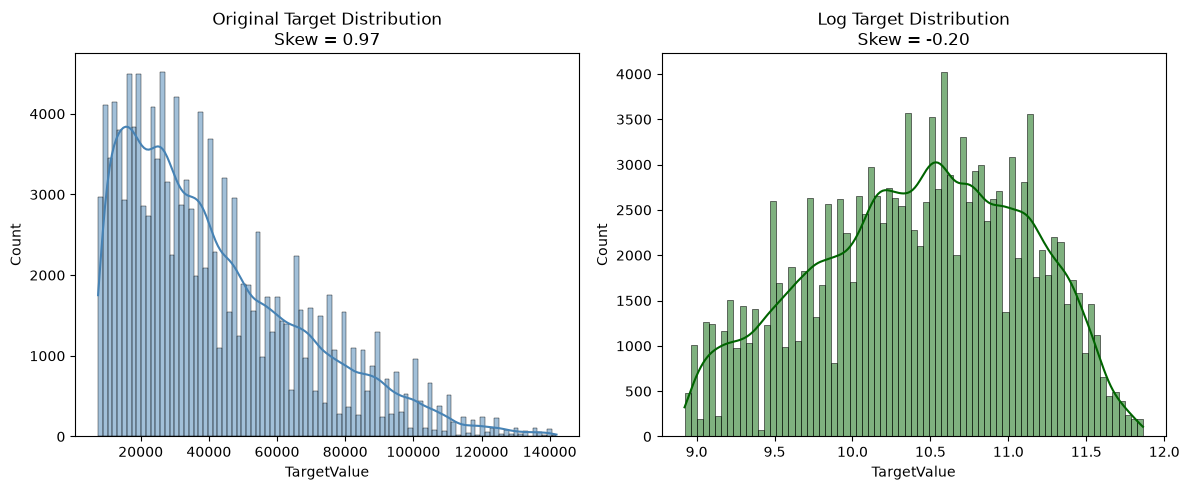


Columns with Highest Missing Percentage
---------------------------------------------
col19    99.952416
col18    99.952416
col5     92.515555
col4     92.515555
col27    89.214930
col28    89.214930
col29    86.393753
col30    86.393753
col13    83.125572
col14    83.125572
dtype: float64


In [4]:

raw_skew = train_raw["TargetValue"].skew()
log_skew = np.log(train_raw["TargetValue"]).skew()
print(f"Skewness (Original): {raw_skew:.4f}")
print(f"Skewness (Log Scale): {log_skew:.4f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(
    train_raw["TargetValue"],
    kde=True,
    ax=axes[0],
    color="steelblue"
)
axes[0].set_title(
    f"Original Target Distribution\nSkew = {raw_skew:.2f}"
)
sns.histplot(
    np.log(train_raw["TargetValue"]),
    kde=True,
    ax=axes[1],
    color="darkgreen"
)
axes[1].set_title(
    f"Log Target Distribution\nSkew = {log_skew:.2f}"
)
plt.tight_layout()
plt.show()
missing_pct = (
    train_raw
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)
print("\nColumns with Highest Missing Percentage")
print("-" * 45)
print(missing_pct.head(10))

In [5]:
def preprocess_data(train_df, test_df):
    print("Starting preprocessing...")
    train_cleaned = train_df.copy(deep=True)
    test_cleaned = test_df.copy(deep=True)
    cols_to_remove = [
        "InventoryGroupDescription",
        "TransactionID",
    ]
    train_cleaned.drop(columns=cols_to_remove, inplace=True, errors="ignore")
    test_cleaned.drop(columns=cols_to_remove, inplace=True, errors="ignore")
    for df in (train_cleaned, test_cleaned):
        df.loc[
            df["ManufactureYear"] == 1001,
            "ManufactureYear"
        ] = np.nan
    for df in (train_cleaned, test_cleaned):
        df["OperationalHoursMeter_missing"] = (
            df["OperationalHoursMeter"].isna()
            | (df["OperationalHoursMeter"] == 0)
        )
        df.loc[
            df["OperationalHoursMeter"] == 0,
            "OperationalHoursMeter"
        ] = np.nan
    train_cleaned["TransactionDate"] = pd.to_datetime(
        train_cleaned["TransactionDate"]
    )
    test_cleaned["TransactionDate"] = pd.to_datetime(
        test_cleaned["TransactionDate"]
    )
    excluded_cols = {
        "TransactionDate",
        "TargetValue",
        "ManufactureYear",
        "OperationalHoursMeter",
        "OperationalHoursMeter_missing",
    }
    for col in train_cleaned.columns:
        if col not in excluded_cols:
            train_cleaned[col] = train_cleaned[col].astype("category")
            if col in test_cleaned.columns:
                test_cleaned[col] = test_cleaned[col].astype("category")
    train_cleaned["OperationalHoursMeter_missing"] = (
        train_cleaned["OperationalHoursMeter_missing"].astype(bool)
    )
    test_cleaned["OperationalHoursMeter_missing"] = (
        test_cleaned["OperationalHoursMeter_missing"].astype(bool)
    )
    return train_cleaned, test_cleaned
train_cl, test_cl = preprocess_data(train_raw, test_raw)
print(f"Processed Train Shape : {train_cl.shape}")
print(f"Processed Test Shape  : {test_cl.shape}")

Starting preprocessing...
Processed Train Shape : (138701, 49)
Processed Test Shape  : (15000, 48)


In [6]:
def feature_engineering(train_df, test_df):
    print("Generating engineered features...")
    train_fe = train_df.copy()
    test_fe = test_df.copy()
    for df in (train_fe, test_fe):
        sale_date = df["TransactionDate"]
        df["SaleYear"] = sale_date.dt.year
        df["SaleQuarter"] = sale_date.dt.quarter
        df["SaleMonth"] = sale_date.dt.month
        df["SaleWeek"] = sale_date.dt.isocalendar().week.astype(int)
        df["SaleDay"] = sale_date.dt.day
        df["SaleDayOfWeek"] = sale_date.dt.dayofweek
        df["SaleDayOfYear"] = sale_date.dt.dayofyear
        df["IsMonthStart"] = sale_date.dt.is_month_start.astype(int)
        df["IsMonthEnd"] = sale_date.dt.is_month_end.astype(int)
        df["IsQuarterStart"] = sale_date.dt.is_quarter_start.astype(int)
        df["IsQuarterEnd"] = sale_date.dt.is_quarter_end.astype(int)
        df["IsYearStart"] = sale_date.dt.is_year_start.astype(int)
        df["IsYearEnd"] = sale_date.dt.is_year_end.astype(int)
        df["MachineAge"] = (
            df["SaleYear"] - df["ManufactureYear"]
        )
        df.loc[
            df["MachineAge"] < 0,
            "MachineAge"
        ] = np.nan
        df["ManufactureYear_missing"] = (
            df["ManufactureYear"]
            .isna()
            .astype(int)
        )
        df.drop(
            columns=["Age"],
            inplace=True,
            errors="ignore",
        )
        spec = df["Spec_BaseClass"].astype(str)
        df["Spec_NumericClass"] = (
            spec
            .str.extract(r"(\d+)")
            .astype(float)
        )
        df["Spec_Prefix"] = (
            spec
            .str.extract(r"^([A-Za-z]+)")
            .fillna("Missing")
        )
    sparse_cols = [
        col
        for col in train_fe.columns
        if col != "TargetValue"
        and train_fe[col].isna().mean() > 0.20
    ]
    for col in sparse_cols:
        indicator = f"{col}_missing"
        if indicator not in train_fe.columns:
            train_fe[indicator] = (
                train_fe[col]
                .isna()
                .astype(int)
            )
            test_fe[indicator] = (
                test_fe[col]
                .isna()
                .astype(int)
            )
    high_card_cols = [
        "ProductConfigID",
        "Spec_FullDescriptor",
        "Spec_BaseClass",
        "Spec_SubClass",
        "Spec_ReleaseSeries",
        "Spec_VariantModifier",
    ]
    for col in high_card_cols:
        freq_map = (
            train_fe[col]
            .value_counts(normalize=True)
            .to_dict()
        )
        train_fe[f"{col}_freq"] = (
            train_fe[col]
            .map(freq_map)
            .fillna(0.0)
        )
        test_fe[f"{col}_freq"] = (
            test_fe[col]
            .map(freq_map)
            .fillna(0.0)
        )
    return train_fe, test_fe
train_fe, test_fe = feature_engineering(train_cl, test_cl)
print(f"Engineered Train Shape : {train_fe.shape}")
print(f"Engineered Test Shape  : {test_fe.shape}")

Generating engineered features...
Engineered Train Shape : (138701, 105)
Engineered Test Shape  : (15000, 104)


In [7]:

X = train_fe.drop(
    columns=["TargetValue", "TransactionDate"],
    errors="ignore",
)
y = np.log(train_fe["TargetValue"])
X_test = test_fe.drop(
    columns=["TargetValue", "TransactionDate"],
    errors="ignore",
)

X_test = X_test.reindex(
    columns=X.columns
)
train_only = sorted(
    set(X.columns) - set(X_test.columns)
)
test_only = sorted(
    set(X_test.columns) - set(X.columns)
)
print("Training-only columns:", train_only)
print("Testing-only columns :", test_only)
assert (
    X.columns.tolist()
    == X_test.columns.tolist()
), "Training/Test feature mismatch detected."
print("Feature alignment check passed successfully.")
categorical_cols = [
    col
    for col in X.columns
    if not pd.api.types.is_numeric_dtype(X[col])
]
for col in categorical_cols:
    X[col] = X[col].astype("category")

    X_test[col] = pd.Categorical(
        X_test[col],
        categories=X[col].cat.categories,
    )
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)
results = dict()
saved_baselines = dict()
feature_order_rf = []
def run_cv(
    model_name,
    model_inst,
    X_data,
    y_data,
    is_linear=False,
    is_rf=False,
):
    print(f"\nTraining baseline model: {model_name}")
    start_time = time.time()
    cv_scores = []
    X_model = X_data.copy()
    if is_linear:
        num_cols = [
            col
            for col in X_model.columns
            if pd.api.types.is_numeric_dtype(X_model[col])
        ]
        cat_cols = [
            col
            for col in X_model.columns
            if (
                not pd.api.types.is_numeric_dtype(X_model[col])
                and X_model[col].nunique() < 100
            )
        ]
        preprocessor = ColumnTransformer(
            transformers=[
                (
                    "num",
                    Pipeline(
                        [
                            (
                                "imputer",
                                SimpleImputer(strategy="median"),
                            ),
                            (
                                "scaler",
                                StandardScaler(),
                            ),
                        ]
                    ),
                    num_cols,
                ),
                (
                    "cat",
                    Pipeline(
                        [
                            (
                                "imputer",
                                SimpleImputer(
                                    strategy="most_frequent"
                                ),
                            ),
                            (
                                "onehot",
                                OneHotEncoder(
                                    handle_unknown="ignore",
                                    sparse_output=False,
                                ),
                            ),
                        ]
                    ),
                    cat_cols,
                ),
            ]
        )
        pipeline = Pipeline(
            steps=[
                (
                    "preprocessor",
                    preprocessor,
                ),
                (
                    "regressor",
                    model_inst,
                ),
            ]
        )
    elif is_rf:
        num_cols = [
            col
            for col in X_model.columns
            if pd.api.types.is_numeric_dtype(X_model[col])
        ]
        cat_cols = [
            col
            for col in X_model.columns
            if not pd.api.types.is_numeric_dtype(X_model[col])
        ]
        global feature_order_rf

        feature_order_rf = num_cols + cat_cols
        preprocessor = ColumnTransformer(
            transformers=[
                (
                    "num",
                    SimpleImputer(
                        strategy="median",
                    ),
                    num_cols,
                ),
                (
                    "cat",
                    Pipeline(
                        [
                            (
                                "imputer",
                                SimpleImputer(
                                    strategy="most_frequent",
                                ),
                            ),
                            (
                                "ordinal",
                                OrdinalEncoder(
                                    handle_unknown="use_encoded_value",
                                    unknown_value=-1,
                                ),
                            ),
                        ]
                    ),
                    cat_cols,
                ),
            ]
        )
        pipeline = Pipeline(
            steps=[
                (
                    "preprocessor",
                    preprocessor,
                ),
                (
                    "regressor",
                    model_inst,
                ),
            ]
        )
    else:
        pipeline = model_inst
    fold = 1
    for train_idx, val_idx in kf.split(X_model):
        fold_start = time.time()
        X_tr = X_model.iloc[train_idx]
        X_va = X_model.iloc[val_idx]
        y_tr = y_data.iloc[train_idx]
        y_va = y_data.iloc[val_idx]
        pipeline.fit(
            X_tr,
            y_tr,
        )
        preds = pipeline.predict(X_va)
        rmse = np.sqrt(
            np.mean(
                (y_va - preds) ** 2
            )
        )
        cv_scores.append(rmse)
        print(
            f"Fold {fold}: RMSE={rmse:.4f} | "
            f"{time.time()-fold_start:.2f}s"
        )
        fold += 1
    mean_score = np.mean(cv_scores)
    std_score = np.std(cv_scores)
    total_time = time.time() - start_time
    print(
        f"{model_name} Mean CV RMSE: "
        f"{mean_score:.5f}"
    )
    pipeline.fit(
        X_model,
        y_data,
    )
    saved_baselines[model_name] = pipeline
    return (
        mean_score,
        std_score,
        total_time,
    )
results["Linear Regression"] = run_cv(
    "Linear Regression",
    LinearRegression(),
    X,
    y,
    is_linear=True,
)
results["Random Forest"] = run_cv(
    "Random Forest",
    RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=4,
        n_jobs=-1,
        random_state=42,
    ),
    X,
    y,
    is_rf=True,
)
results["XGBoost"] = run_cv(
    "XGBoost",
    xgb.XGBRegressor(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        n_jobs=-1,
        enable_categorical=True,
        random_state=42,
    ),
    X,
    y,
)
results["LightGBM"] = run_cv(
    "LightGBM",
    lgb.LGBMRegressor(
        n_estimators=150,
        max_depth=8,
        learning_rate=0.1,
        n_jobs=-1,
        random_state=42,
        verbosity=-1,
    ),
    X,
    y,
)


Training-only columns: []
Testing-only columns : []
Feature alignment check passed successfully.

Training baseline model: Linear Regression
Fold 1: RMSE=0.3388 | 8.51s
Fold 2: RMSE=0.3387 | 7.39s
Fold 3: RMSE=0.3400 | 8.29s
Fold 4: RMSE=0.3416 | 4.89s
Fold 5: RMSE=0.3372 | 4.55s
Linear Regression Mean CV RMSE: 0.33923

Training baseline model: Random Forest
Fold 1: RMSE=0.2735 | 24.85s
Fold 2: RMSE=0.2730 | 27.42s
Fold 3: RMSE=0.2756 | 28.66s
Fold 4: RMSE=0.2770 | 27.22s
Fold 5: RMSE=0.2724 | 28.59s
Random Forest Mean CV RMSE: 0.27429

Training baseline model: XGBoost
Fold 1: RMSE=0.2330 | 46.53s
Fold 2: RMSE=0.2349 | 44.28s
Fold 3: RMSE=0.2352 | 46.36s
Fold 4: RMSE=0.2356 | 47.45s
Fold 5: RMSE=0.2339 | 43.36s
XGBoost Mean CV RMSE: 0.23452

Training baseline model: LightGBM
Fold 1: RMSE=0.2148 | 2.17s
Fold 2: RMSE=0.2178 | 2.27s
Fold 3: RMSE=0.2178 | 2.48s
Fold 4: RMSE=0.2197 | 2.58s
Fold 5: RMSE=0.2173 | 2.31s
LightGBM Mean CV RMSE: 0.21746


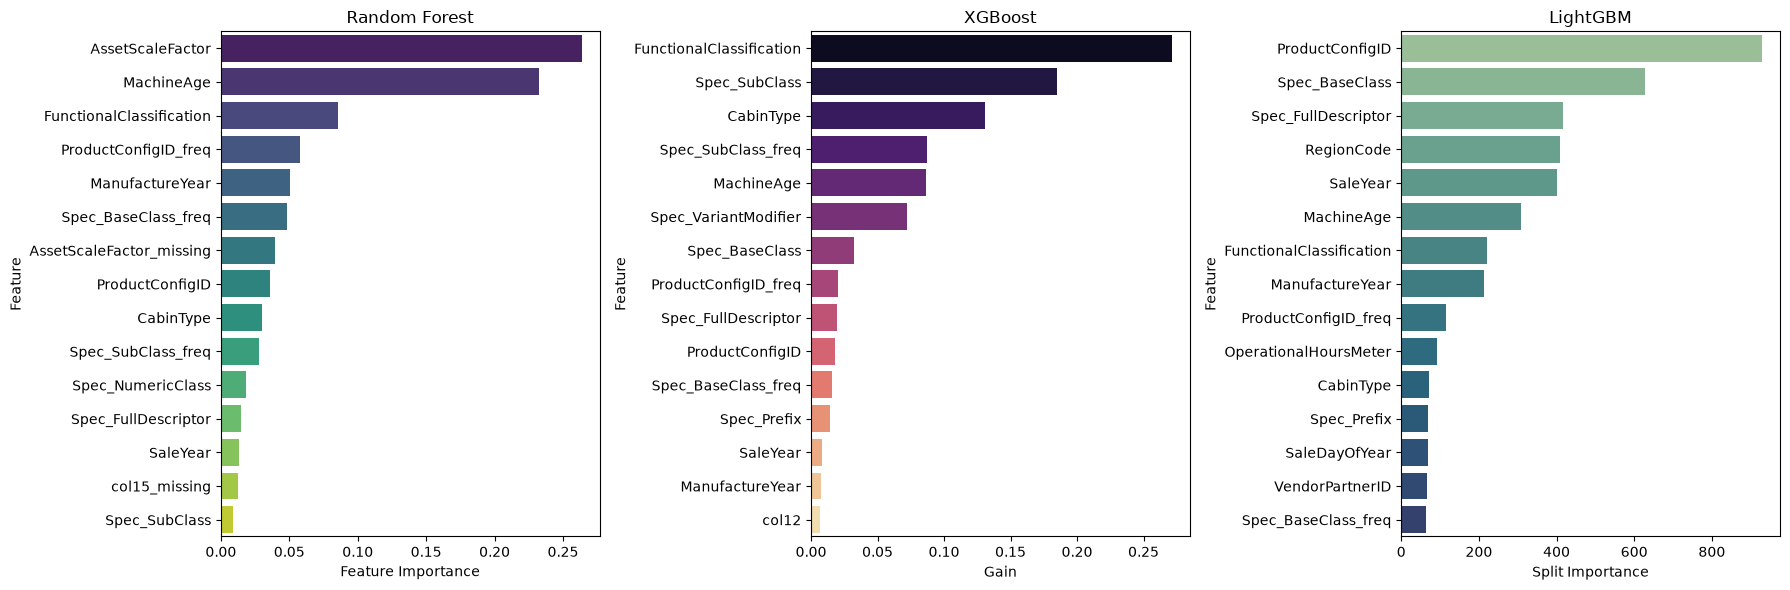

In [8]:
plt.figure(figsize=(18, 6))
rf_pipeline = saved_baselines["Random Forest"]
rf_importances = (
    pd.Series(
        rf_pipeline.named_steps["regressor"].feature_importances_,
        index=feature_order_rf,
    )
    .sort_values(ascending=False)
    .head(15)
)
plt.subplot(1, 3, 1)
sns.barplot(
    x=rf_importances.values,
    y=rf_importances.index,
    hue=rf_importances.index,
    legend=False,
    palette="viridis",
)
plt.title("Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
xgb_model = saved_baselines["XGBoost"]
xgb_importances = (
    pd.Series(
        xgb_model.feature_importances_,
        index=X.columns,
    )
    .sort_values(ascending=False)
    .head(15)
)
plt.subplot(1, 3, 2)
sns.barplot(
    x=xgb_importances.values,
    y=xgb_importances.index,
    hue=xgb_importances.index,
    legend=False,
    palette="magma",
)
plt.title("XGBoost")
plt.xlabel("Gain")
plt.ylabel("Feature")
lgb_model = saved_baselines["LightGBM"]
lgb_importances = (
    pd.Series(
        lgb_model.feature_importances_,
        index=X.columns,
    )
    .sort_values(ascending=False)
    .head(15)
)
plt.subplot(1, 3, 3)
sns.barplot(
    x=lgb_importances.values,
    y=lgb_importances.index,
    hue=lgb_importances.index,
    legend=False,
    palette="crest",
)
plt.title("LightGBM")
plt.xlabel("Split Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [9]:
print("=== Preparing Sample for Hyperparameter Optimization ===")
sample_size = min(40000, len(X))
rng = np.random.default_rng(42)
sample_idx = rng.choice(
    len(X),
    size=sample_size,
    replace=False,
)

X_sample = X.iloc[sample_idx].copy()
y_sample = y.iloc[sample_idx].copy()
X_tr_s, X_va_s, y_tr_s, y_va_s = train_test_split(
    X_sample,
    y_sample,
    test_size=0.20,
    random_state=42,
)
print("=== LightGBM Hyperparameter Optimization ===")
def lgb_objective(trial):
    params = {
        "num_leaves": trial.suggest_int(
            "num_leaves",
            31,
            255,
        ),
        "max_depth": trial.suggest_int(
            "max_depth",
            6,
            12,
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate",
            0.03,
            0.20,
            log=True,
        ),
        "min_child_samples": trial.suggest_int(
            "min_child_samples",
            10,
            100,
        ),
        "feature_fraction": trial.suggest_float(
            "feature_fraction",
            0.60,
            1.00,
        ),
        "bagging_fraction": trial.suggest_float(
            "bagging_fraction",
            0.60,
            1.00,
        ),
        "bagging_freq": trial.suggest_int(
            "bagging_freq",
            1,
            7,
        ),
        "lambda_l1": trial.suggest_float(
            "lambda_l1",
            1e-8,
            10.0,
            log=True,
        ),
        "lambda_l2": trial.suggest_float(
            "lambda_l2",
            1e-8,
            10.0,
            log=True,
        ),
        "n_estimators": 1000,

        "random_state": 42,

        "verbosity": -1,

        "n_jobs": -1,
    }
    model = lgb.LGBMRegressor(
        **params
    )
    model.fit(
        X_tr_s,
        y_tr_s,
        eval_set=[
            (
                X_va_s,
                y_va_s,
            )
        ],
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=20,
                verbose=False,
            )
        ],
    )
    predictions = model.predict(
        X_va_s
    )
    score = np.sqrt(
        np.mean(
            (y_va_s - predictions) ** 2
        )
    )
    return score
lgb_study = optuna.create_study(
    direction="minimize"
)
lgb_study.optimize(
    lgb_objective,
    n_trials=10,
)
best_lgb_params = lgb_study.best_params
print(
    "Optimal LightGBM Parameters:"
)
print(best_lgb_params)
print("\n=== XGBoost Hyperparameter Optimization ===")
def xgb_objective(trial):
    params = {
        "learning_rate": trial.suggest_float(
            "learning_rate",
            0.03,
            0.20,
            log=True,
        ),
        "max_depth": trial.suggest_int(
            "max_depth",
            4,
            10,
        ),
        "min_child_weight": trial.suggest_int(
            "min_child_weight",
            1,
            20,
        ),
        "subsample": trial.suggest_float(
            "subsample",
            0.60,
            1.00,
        ),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree",
            0.60,
            1.00,
        ),
        "gamma": trial.suggest_float(
            "gamma",
            1e-8,
            1.0,
            log=True,
        ),
        "reg_alpha": trial.suggest_float(
            "reg_alpha",
            1e-8,
            10.0,
            log=True,
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda",
            1e-8,
            10.0,
            log=True,
        ),
        "n_estimators": 1000,
        "random_state": 42,
        "n_jobs": -1,
        "enable_categorical": True,
        "early_stopping_rounds": 20,
    }
    model = xgb.XGBRegressor(
        **params
    )
    model.fit(
        X_tr_s,
        y_tr_s,
        eval_set=[
            (
                X_va_s,
                y_va_s,
            )
        ],
        verbose=False,
    )
    predictions = model.predict(
        X_va_s
    )
    score = np.sqrt(
        np.mean(
            (y_va_s - predictions) ** 2
        )
    )
    return score

xgb_study = optuna.create_study(direction='minimize')
xgb_study = optuna.create_study(
    direction="minimize"
)
xgb_study.optimize(
    xgb_objective,
    n_trials=10,
)
best_xgb_params = xgb_study.best_params
print("Optimal XGBoost Parameters:")
print(best_xgb_params)
print("\n=== 5-Fold CV : Tuned LightGBM ===")
lgb_cv_scores = []
lgb_iters = []
lgb_full_params = best_lgb_params.copy()
lgb_full_params["random_state"] = 42
lgb_full_params["n_jobs"] = -1
lgb_full_params["verbosity"] = -1
for train_idx, val_idx in kf.split(X):
    X_tr = X.iloc[train_idx]
    X_va = X.iloc[val_idx]
    y_tr = y.iloc[train_idx]
    y_va = y.iloc[val_idx]
    model = lgb.LGBMRegressor(
        n_estimators=1000,
        **lgb_full_params,
    )
    model.fit(
        X_tr,
        y_tr,
        eval_set=[
            (
                X_va,
                y_va,
            )
        ],
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=25,
                verbose=False,
            )
        ],
    )
    lgb_iters.append(
        model.best_iteration_
    )
    predictions = model.predict(
        X_va
    )
    lgb_cv_scores.append(
        np.sqrt(
            np.mean(
                (y_va - predictions) ** 2
            )
        )
    )
lgb_tuned_score = np.mean(
    lgb_cv_scores
)
print(
    f"LightGBM Mean RMSE : {lgb_tuned_score:.5f}"
)
print("\n=== 5-Fold CV : Tuned XGBoost ===")
xgb_cv_scores = []
xgb_iters = []
xgb_full_params = best_xgb_params.copy()
xgb_full_params["random_state"] = 42
xgb_full_params["n_jobs"] = -1
xgb_full_params["enable_categorical"] = True
xgb_full_params["early_stopping_rounds"] = 25
for train_idx, val_idx in kf.split(X):
    X_tr = X.iloc[train_idx]
    X_va = X.iloc[val_idx]
    y_tr = y.iloc[train_idx]
    y_va = y.iloc[val_idx]
    model = xgb.XGBRegressor(
        n_estimators=1000,
        **xgb_full_params,
    )
    model.fit(
        X_tr,
        y_tr,
        eval_set=[
            (
                X_va,
                y_va,
            )
        ],
        verbose=False,
    )
    xgb_iters.append(
        model.best_iteration
    )
    predictions = model.predict(
        X_va
    )
    xgb_cv_scores.append(
        np.sqrt(
            np.mean(
                (y_va - predictions) ** 2
            )
        )
    )
xgb_tuned_score = np.mean(
    xgb_cv_scores
)
print(
    f"XGBoost Mean RMSE : {xgb_tuned_score:.5f}"
)
print("\nTraining final optimized models...")
lgb_final = lgb.LGBMRegressor(
    n_estimators=max(
        1,
        int(np.mean(lgb_iters)),
    ),
    **lgb_full_params,
)
lgb_final.fit(
    X,
    y,
)
xgb_final_params = xgb_full_params.copy()
xgb_final_params.pop(
    "early_stopping_rounds",
    None,
)
xgb_final = xgb.XGBRegressor(
    n_estimators=max(
        1,
        int(np.mean(xgb_iters)),
    ),
    **xgb_final_params,
)
xgb_final.fit(
    X,
    y,
)
with open(
    "lightgbm_tuned.pkl",
    "wb",
) as f:
    pickle.dump(
        lgb_final,
        f,
    )
with open(
    "xgboost_tuned.pkl",
    "wb",
) as f:
    pickle.dump(
        xgb_final,
        f,
    )
print("Optimized models saved successfully.")


=== Preparing Sample for Hyperparameter Optimization ===
=== LightGBM Hyperparameter Optimization ===
Optimal LightGBM Parameters:
{'num_leaves': 77, 'max_depth': 12, 'learning_rate': 0.03552264844913578, 'min_child_samples': 15, 'feature_fraction': 0.7824837902312061, 'bagging_fraction': 0.9345229516491667, 'bagging_freq': 3, 'lambda_l1': 0.11085837847734809, 'lambda_l2': 0.004183452944487737}

=== XGBoost Hyperparameter Optimization ===
Optimal XGBoost Parameters:
{'learning_rate': 0.036043448265551524, 'max_depth': 8, 'min_child_weight': 20, 'subsample': 0.8049481637052593, 'colsample_bytree': 0.636737699326085, 'gamma': 9.627250905081918e-06, 'reg_alpha': 1.2158642244441968e-05, 'reg_lambda': 1.927694274325698e-06}

=== 5-Fold CV : Tuned LightGBM ===
LightGBM Mean RMSE : 0.20524

=== 5-Fold CV : Tuned XGBoost ===
XGBoost Mean RMSE : 0.20557

Training final optimized models...
Optimized models saved successfully.


In [10]:
import pandas as pd
import numpy as np
import pandas as pd
train = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv")
test = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv")
print(train.shape)
print(test.shape)
dummy_predictions = np.ones(len(test_raw))
submission = pd.DataFrame({
    "TransactionID": test_raw["TransactionID"],
    "TargetValue": dummy_predictions
})
submission.to_csv("submission.csv", index=False)
print("submission.csv created successfully!")
print(submission.head())
assert len(submission) == len(test_raw)
assert submission["TransactionID"].equals(test_raw["TransactionID"])
assert submission["TargetValue"].notna().all()
assert np.isfinite(submission["TargetValue"]).all()

print("All checks passed.")

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv'

In [ ]:
import os
import pickle
import numpy as np
import pandas as pd
DATA_PATH = "."
if os.path.exists("/kaggle/input"):
    for root, dirs, files in os.walk("/kaggle/input"):
        if "test.csv" in files:
            DATA_PATH = root
            break
print("Using:", DATA_PATH)
test_raw = pd.read_csv(os.path.join(DATA_PATH, "test.csv"))
sample_sub = pd.read_csv(os.path.join(DATA_PATH, "sample_submission.csv"))
with open("lightgbm_tuned.pkl", "rb") as f:
    lgb_model = pickle.load(f)
with open("xgboost_tuned.pkl", "rb") as f:
    xgb_model = pickle.load(f)
lgb_pred = lgb_model.predict(X_test)
xgb_pred = xgb_model.predict(X_test)
pred = 0.60 * xgb_pred + 0.40 * lgb_pred
pred = np.maximum(0, np.expm1(pred))
target_col = [c for c in sample_sub.columns if c != "TransactionID"][0]
submission = sample_sub.copy()
submission[target_col] = pred
submission.to_csv("submission.csv", index=False)
print("submission.csv created successfully!")
print(submission.head())
assert len(submission) == len(sample_sub)
assert submission["TransactionID"].equals(sample_sub["TransactionID"])
assert submission[target_col].notna().all()
assert np.isfinite(submission[target_col]).all()
print("Submission validation passed.")